# Cálculo Numérico – Atividade Prática III
Métodos da **bisseção**, de **Newton** e da **secante** para encontrar raízes.

**Critério de parada adotado:** o método para quando, ao mesmo tempo,
`|x_{k+1} - x_k| < tol` **e** `|f(x_{k+1})| < tol`.
Usar os dois evita parar cedo demais: um passo pequeno não garante que
f seja pequena (curva muito inclinada) e um resíduo pequeno não garante
que x esteja estabilizado (curva muito plana).
Na bisseção, `|x_{k+1} - x_k|` é a metade da largura do intervalo.

**Falhas detectadas:** f(a)f(b) > 0 (bisseção), |f'(x_k)| ≈ 0 (Newton),
denominador ≈ 0 (secante), valores não finitos e falta de convergência
em `max_iter` iterações.

In [ ]:
# ===================== PARÂMETROS (altere aqui) =====================
TOL = 1e-6          # tolerância
MAX_ITER = 100      # número máximo de iterações
EPS_DIV = 1e-12     # abaixo disso, derivada/denominador é "quase zero"
PASTA_SAIDA = "saida"   # onde salvar GIFs e tabela

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter

os.makedirs(PASTA_SAIDA, exist_ok=True)

## Parte 1 – Implementação dos métodos
Cada método devolve um dicionário com: `raiz`, `iteracoes`, `historico`
(aproximação de cada iteração), `convergiu`, `mensagem` e `passos`
(dados extras usados nas animações).

In [ ]:
def _resultado(raiz, historico, convergiu, mensagem, passos):
    return {"raiz": raiz, "iteracoes": len(historico), "historico": historico,
            "convergiu": convergiu, "mensagem": mensagem, "passos": passos}


def bissecao(f, a, b, tol=TOL, max_iter=MAX_ITER):
    """Bisseção em [a, b]. passos = lista de (a_k, b_k, c_k)."""
    fa, fb = f(a), f(b)
    if fa * fb > 0:
        return _resultado(np.nan, [], False, "f(a)f(b) > 0: sem garantia de raiz", [])
    hist, passos = [], []
    c = a
    for _ in range(max_iter):
        c = (a + b) / 2
        fc = f(c)
        passos.append((a, b, c))
        hist.append(c)
        if abs(fc) < tol and (b - a) / 2 < tol:   # passo = metade do intervalo
            return _resultado(c, hist, True, "convergiu", passos)
        if fa * fc < 0:
            b, fb = c, fc
        else:
            a, fa = c, fc
    return _resultado(c, hist, False, "máximo de iterações atingido", passos)


def newton(f, df, x0, tol=TOL, max_iter=MAX_ITER):
    """Newton. passos = lista de x_k (o ponto onde se traça a tangente)."""
    x = x0
    hist, passos = [], []
    for _ in range(max_iter):
        dfx = df(x)
        if abs(dfx) < EPS_DIV:
            return _resultado(x, hist, False, "f'(x_k) ≈ 0", passos)
        x_novo = x - f(x) / dfx
        passos.append(x)
        hist.append(x_novo)
        if not np.isfinite(x_novo):
            return _resultado(x_novo, hist, False, "valor não finito", passos)
        if abs(x_novo - x) < tol and abs(f(x_novo)) < tol:
            return _resultado(x_novo, hist, True, "convergiu", passos)
        x = x_novo
    return _resultado(x, hist, False, "máximo de iterações atingido", passos)


def secante(f, x0, x1, tol=TOL, max_iter=MAX_ITER):
    """Secante. passos = lista de (x_{k-1}, x_k, x_{k+1})."""
    hist, passos = [], []
    for _ in range(max_iter):
        f0, f1 = f(x0), f(x1)
        den = f1 - f0
        if abs(den) < EPS_DIV:
            return _resultado(x1, hist, False, "denominador ≈ 0", passos)
        x2 = x1 - f1 * (x1 - x0) / den
        passos.append((x0, x1, x2))
        hist.append(x2)
        if not np.isfinite(x2):
            return _resultado(x2, hist, False, "valor não finito", passos)
        if abs(x2 - x1) < tol and abs(f(x2)) < tol:
            return _resultado(x2, hist, True, "convergiu", passos)
        x0, x1 = x1, x2
    return _resultado(x1, hist, False, "máximo de iterações atingido", passos)

## Funções investigadas

In [ ]:
FUNCOES = {
    "f1(x) = x² − 2":       (lambda x: x**2 - 2,          lambda x: 2*x),
    "f2(x) = x³ − x − 2":   (lambda x: x**3 - x - 2,      lambda x: 3*x**2 - 1),
    "f3(x) = e^(−x) − x":   (lambda x: np.exp(-x) - x,    lambda x: -np.exp(-x) - 1),
    "f4(x) = x³ − 2x + 2":  (lambda x: x**3 - 2*x + 2,    lambda x: 3*x**2 - 2),
}
nomes = list(FUNCOES)

# Casos: (função, intervalo bisseção, x0 Newton, (x0, x1) secante) – valores sugeridos
CASOS = [
    (nomes[0], (1, 2),   1.5,  (1, 2)),
    (nomes[1], (1, 2),   1.5,  (1, 2)),
    (nomes[2], (0, 1),   0.5,  (0, 1)),
    (nomes[3], (-2, -1), -2.0, (-2, -1)),
]

# Testes extras (escolhidos para mostrar falhas; justificativa no relatório):
#  - f4 com Newton em x0 = 0: a iteração oscila 0 → 1 → 0 → ... (ciclo)
#  - f4 com bisseção em [0, 1]: f(0)f(1) > 0, o método deve recusar o intervalo
#  - f4 com Newton em x0 = 0.8165: f'(x0) ≈ 0 (ponto crítico), tangente quase horizontal
EXTRAS = [
    (nomes[3], "Newton",  (0.0,)),
    (nomes[3], "Bisseção", (0, 1)),
    (nomes[3], "Newton",  (float(np.sqrt(2/3)),)),
]

In [ ]:
def executar(nome_f, metodo, vi):
    f, df = FUNCOES[nome_f]
    if metodo == "Bisseção":
        return bissecao(f, *vi)
    if metodo == "Newton":
        return newton(f, df, *vi)
    return secante(f, *vi)

## Parte 2 – Tabela de resultados

In [ ]:
linhas = []
def registrar(nome_f, metodo, vi):
    r = executar(nome_f, metodo, vi)
    f = FUNCOES[nome_f][0]
    if r["iteracoes"] > 0 or np.isfinite(r["raiz"]):
        res = f"{abs(f(r['raiz'])):.2e}" if np.isfinite(r["raiz"]) else "—"
    else:
        res = "—"
    if r["convergiu"]:
        final = f"{r['iteracoes']} iterações"
    else:
        final = f"FALHA: {r['mensagem']} (após {r['iteracoes']} it.)"
    raiz = f"{r['raiz']:.8f}" if np.isfinite(r["raiz"]) else "—"
    vi_txt = f"{vi[0]:.4g}" if metodo == "Newton" else f"[{vi[0]:g}, {vi[1]:g}]" if metodo == "Bisseção" else f"({vi[0]:g}, {vi[1]:g})"
    linhas.append({"Função": nome_f, "Método": metodo, "Valores iniciais": vi_txt,
                   "Raiz aproximada": raiz, "|f(x)| final": res,
                   "Iterações/resultado": final})

for nome_f, ab, x0, xs in CASOS:
    registrar(nome_f, "Bisseção", ab)
    registrar(nome_f, "Newton", (x0,))
    registrar(nome_f, "Secante", xs)
for nome_f, metodo, vi in EXTRAS:
    registrar(nome_f, metodo, vi)

tabela = pd.DataFrame(linhas)
tabela.to_csv(os.path.join(PASTA_SAIDA, "tabela_resultados.csv"), index=False)
print(tabela.to_string(index=False))

             Função   Método Valores iniciais Raiz aproximada |f(x)| final                                    Iterações/resultado
     f1(x) = x² − 2 Bisseção           [1, 2]      1.41421366     2.69e-07                                           21 iterações
     f1(x) = x² − 2   Newton              1.5      1.41421356     4.44e-16                                            4 iterações
     f1(x) = x² − 2  Secante           (1, 2)      1.41421356     8.88e-16                                            6 iterações
 f2(x) = x³ − x − 2 Bisseção           [1, 2]      1.52137971     1.45e-08                                           22 iterações
 f2(x) = x³ − x − 2   Newton              1.5      1.52137971     4.53e-14                                            3 iterações
 f2(x) = x³ − x − 2  Secante           (1, 2)      1.52137971     1.84e-14                                            7 iterações
 f3(x) = e^(−x) − x Bisseção           [0, 1]      0.56714344     2.35e-07                

## Parte 3 – Animações (GIF)

In [ ]:
def animar(nome_f, metodo, vi, xlim, arquivo, fps=1.2, max_quadros=15):
    f, df = FUNCOES[nome_f]
    r = executar(nome_f, metodo, vi)
    passos = r["passos"]
    n = min(len(passos), max_quadros)   # limita o tamanho do GIF (útil em ciclos)
    xs = np.linspace(*xlim, 600)
    ys = f(xs)
    yl = (min(ys.min(), -0.5), max(ys.max(), 0.5))
    ymargem = 0.08 * (yl[1] - yl[0])
    yl = (yl[0] - ymargem, yl[1] + ymargem)

    fig, ax = plt.subplots(figsize=(7, 4.6))

    def quadro(k):
        ax.clear()
        ax.plot(xs, ys, color="tab:blue", lw=2, label=nome_f)
        ax.axhline(0, color="k", lw=1)
        ax.set_xlim(*xlim); ax.set_ylim(*yl)
        ax.grid(alpha=0.3)
        if metodo == "Bisseção":
            a, b, c = passos[k]
            ax.plot([a, b], [0, 0], color="tab:orange", lw=6, solid_capstyle="butt",
                    label="intervalo [a, b]")
            for v in (a, b):
                ax.axvline(v, color="tab:orange", ls="--", lw=1)
            ax.plot(c, f(c), "ro", label="ponto médio c")
            ax.plot(c, 0, "rx")
        elif metodo == "Newton":
            for j in range(k):                     # tangentes anteriores (esmaecidas)
                xj = passos[j]
                ax.plot(xs, f(xj) + df(xj)*(xs - xj), color="gray", lw=0.8, alpha=0.4)
            xk = passos[k]
            ax.plot(xs, f(xk) + df(xk)*(xs - xk), color="tab:orange", lw=1.6,
                    label="tangente em x_k")
            ax.plot(xk, f(xk), "go", label="(x_k, f(x_k))")
            xn = r["historico"][k]
            ax.plot([xk, xn], [f(xk), 0], "k:", lw=0.8)
            ax.plot(xn, 0, "rx", ms=9, mew=2, label="x_{k+1}")
        else:
            for j in range(k):
                p, q, _ = passos[j]
                ax.plot(xs, f(q) + (f(q)-f(p))/(q-p)*(xs - q), color="gray", lw=0.8, alpha=0.4)
            p, q, s = passos[k]
            ax.plot(xs, f(q) + (f(q)-f(p))/(q-p)*(xs - q), color="tab:orange", lw=1.6,
                    label="reta secante")
            ax.plot([p, q], [f(p), f(q)], "go", label="pontos usados")
            ax.plot(s, 0, "rx", ms=9, mew=2, label="x_{k+1}")
        xa = r["historico"][k]
        ax.set_title(f"{metodo} – {nome_f}\n"
                     f"iteração {k+1}/{n}   x = {xa:.8f}   |f(x)| = {abs(f(xa)):.2e}",
                     fontsize=10)
        ax.legend(loc="best", fontsize=8)

    anim = FuncAnimation(fig, quadro, frames=n, repeat=True)
    caminho = os.path.join(PASTA_SAIDA, arquivo)
    anim.save(caminho, writer=PillowWriter(fps=fps))
    plt.close(fig)
    print("GIF salvo:", caminho)
    return caminho

In [ ]:
gifs = [
    animar(nomes[0], "Bisseção", (1, 2), (0.8, 2.2), "bissecao_f1.gif", fps=2),
    animar(nomes[1], "Newton", (1.5,), (0.8, 2.2), "newton_f2.gif"),
    animar(nomes[2], "Secante", (0, 1), (-0.2, 1.2), "secante_f3.gif"),
    # extra: Newton em ciclo (não converge)
    animar(nomes[3], "Newton", (0.0,), (-2.2, 1.6), "newton_f4_ciclo.gif", fps=3),
]

GIF salvo: saida/bissecao_f1.gif
GIF salvo: saida/newton_f2.gif
GIF salvo: saida/secante_f3.gif
GIF salvo: saida/newton_f4_ciclo.gif


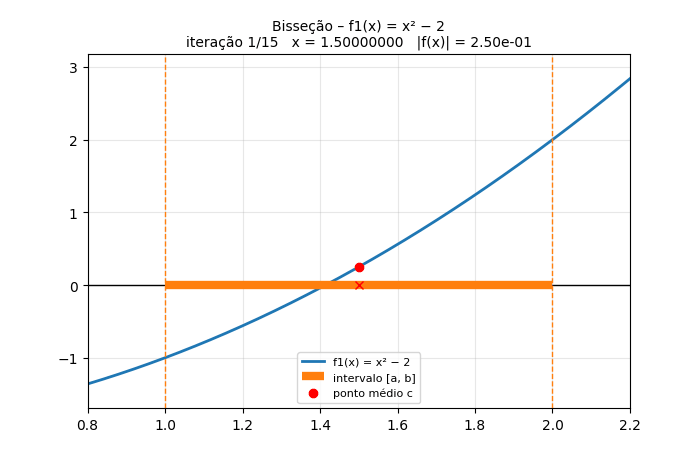

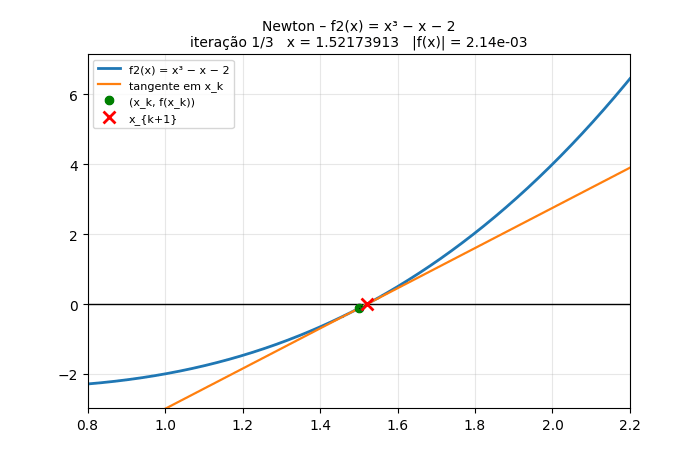

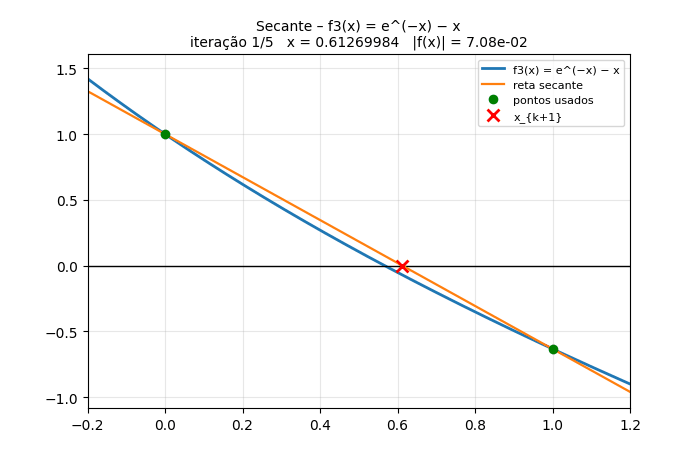

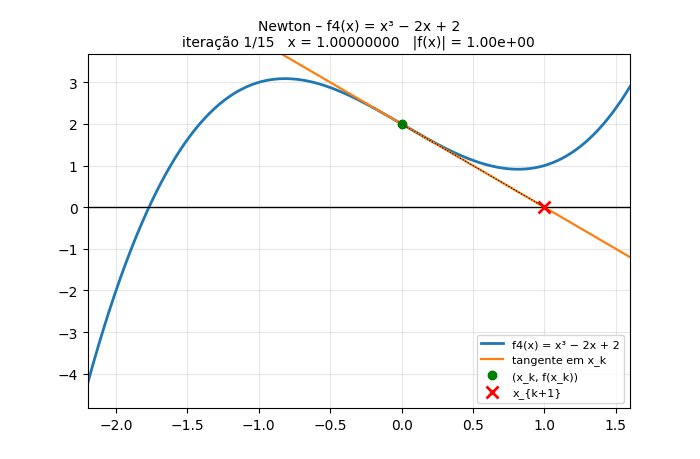

In [ ]:
try:
    from IPython.display import Image, display
    for g in gifs:
        display(Image(filename=g))
except Exception:
    pass